In [1]:
import torch
import numpy as np
from PIL import Image
import time
import pandas as pd

#### Instalar: 
    lightning                 2.1.4


In [2]:
!pip install lightning==2.1.4

Defaulting to user installation because normal site-packages is not writeable


In [3]:
from model import GetModel

device = 'cuda'
model = GetModel(device=device)

In [4]:
im = Image.open('./DATA/many_curves_holonomic/1.png')
im = np.array(im.resize((16,12)))/255.0

v, w = model(im)
print('V: {}, W: {}'.format(v, w))

V: 5.006191074848175, W: -0.007601022720336914


In [5]:
iters = 200
start = time.time()
seq = []
for i in range(iters):
    im = Image.open('./DATA/many_curves_holonomic/{}.png'.format(i+1))
    im = np.array(im.resize((16,12)))/255.0

    v, w = model(im)
    seq.append([v, w])
end = time.time()
print('FPS: {}'.format(iters/(end-start)))

FPS: 168.0731117138348


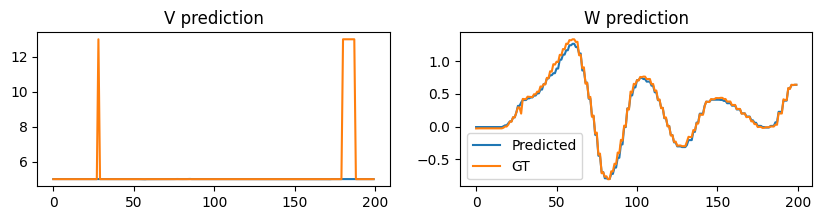

In [6]:
import matplotlib.pyplot as plt

seq = np.asarray(seq)
fig, ax = plt.subplots(1,2, figsize=(10,2))
ax[0].plot(seq[:,0])
ax[0].set_title('V prediction')
ax[1].plot(seq[:,1])
ax[1].set_title('W prediction')


gt= pd.read_csv('DATA/many_curves_holonomic/data.csv')[['v', 'w']].to_numpy()
gt = gt[0:200,:]
ax[0].plot(gt[:,0])
ax[0].set_title('V prediction')
ax[1].plot(gt[:,1])
ax[1].set_title('W prediction')
plt.legend(['Predicted', 'GT'])
plt.show()